# Deep Learning Assignment 5 – CO5
## Complete Colab implementation: Student A, Student B and Joint Work



In [1]:
import os, time, math, random, zipfile, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
SEED=42
random.seed(SEED); np.random.seed(SEED)
import sklearn, tensorflow as tf
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import BernoulliRBM
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.neighbors import NearestNeighbors
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)
OUT="/content/Assignment5_CO5_Results"; os.makedirs(OUT,exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(f"{OUT}/{name}",dpi=150,bbox_inches="tight"); plt.show()
print("TensorFlow",tf.__version__,"scikit-learn",sklearn.__version__)
print("GPU:",tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 scikit-learn 1.6.1
GPU: []


## Q1 – Understanding an Energy-Based Model

In [2]:
def energy(v1,v2,h,b1=.5,b2=-.5,c=0,w1=1,w2=1):
    return -(b1*v1+b2*v2+c*h+w1*v1*h+w2*v2*h)
def enumerate_states(w2=1):
    rows=[]
    for v1 in (0,1):
        for v2 in (0,1):
            for h in (0,1):
                e=energy(v1,v2,h,w2=w2); rows.append([v1,v2,h,e,np.exp(-e)])
    d=pd.DataFrame(rows,columns=["v1_dosa","v2_coffee","h","energy","exp_minus_energy"])
    Z=d.exp_minus_energy.sum(); d["probability"]=d.exp_minus_energy/Z
    return d,Z
q1,Z=enumerate_states(1); q1_changed,Z_changed=enumerate_states(-1)
print("All states, original w2=1; Z =",Z); display(q1)
print("Most likely original state:"); display(q1.loc[[q1.probability.idxmax()]])
print("Changed w2=-1; Z =",Z_changed); display(q1_changed)
print("Most likely state after w2 change:"); display(q1_changed.loc[[q1_changed.probability.idxmax()]])
sigmoid=lambda x:1/(1+np.exp(-x))
q1h=pd.DataFrame([[a,b,sigmoid(a+b)] for a in (0,1) for b in (0,1)],
                 columns=["v1_dosa","v2_coffee","P_h1_given_v"])
display(q1h)
print("Joint binary states for 784 visible + 500 hidden units = 2^1284")
print("log10(number of states) =",1284*np.log10(2))
q1.to_csv(f"{OUT}/Q1_states.csv",index=False); q1_changed.to_csv(f"{OUT}/Q1_states_w2_minus1.csv",index=False)
q1h.to_csv(f"{OUT}/Q1_hidden_probabilities.csv",index=False)

All states, original w2=1; Z = 18.774718370381606


,v1_dosa,v2_coffee,h,energy,exp_minus_energy,probability
0,0,0,0,-0.0,1.000000,0.053263
1,0,0,1,-0.0,1.000000,0.053263
2,0,1,0,0.5,0.606531,0.032306
3,0,1,1,-0.5,1.648721,0.087816
4,1,0,0,-0.5,1.648721,0.087816
5,1,0,1,-1.5,4.481689,0.238709
6,1,1,0,-0.0,1.000000,0.053263
7,1,1,1,-2.0,7.389056,0.393564


Most likely original state:


,v1_dosa,v2_coffee,h,energy,exp_minus_energy,probability
7,1,1,1,-2.0,7.389056,0.393564


Changed w2=-1; Z = 10.960071160899256


,v1_dosa,v2_coffee,h,energy,exp_minus_energy,probability
0,0,0,0,-0.0,1.000000,0.091240
1,0,0,1,-0.0,1.000000,0.091240
2,0,1,0,0.5,0.606531,0.055340
3,0,1,1,1.5,0.223130,0.020358
4,1,0,0,-0.5,1.648721,0.150430
5,1,0,1,-1.5,4.481689,0.408911
6,1,1,0,-0.0,1.000000,0.091240
7,1,1,1,-0.0,1.000000,0.091240


Most likely state after w2 change:


,v1_dosa,v2_coffee,h,energy,exp_minus_energy,probability
5,1,0,1,-1.5,4.481689,0.408911


,v1_dosa,v2_coffee,P_h1_given_v
0,0,0,0.500000
1,0,1,0.731059
2,1,0,0.731059
3,1,1,0.880797


Joint binary states for 784 visible + 500 hidden units = 2^1284
log10(number of states) = 386.5225144325519


## Q2 – Training a Restricted Boltzmann Machine

,hidden_units,learning_rate,iterations,average_test_pseudo_likelihood,training_seconds
0,16,0.05,20,-19.742683,1.882945
1,64,0.05,20,-19.826256,2.243067


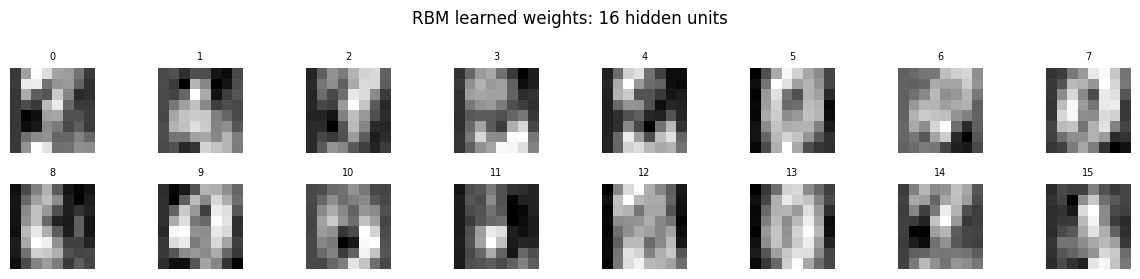

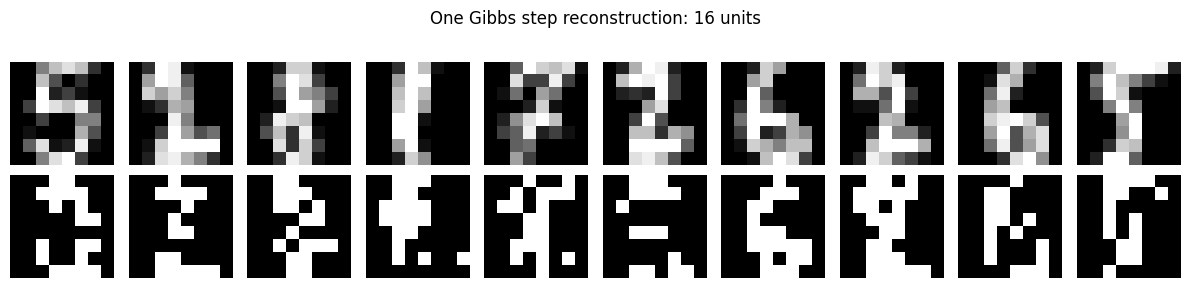

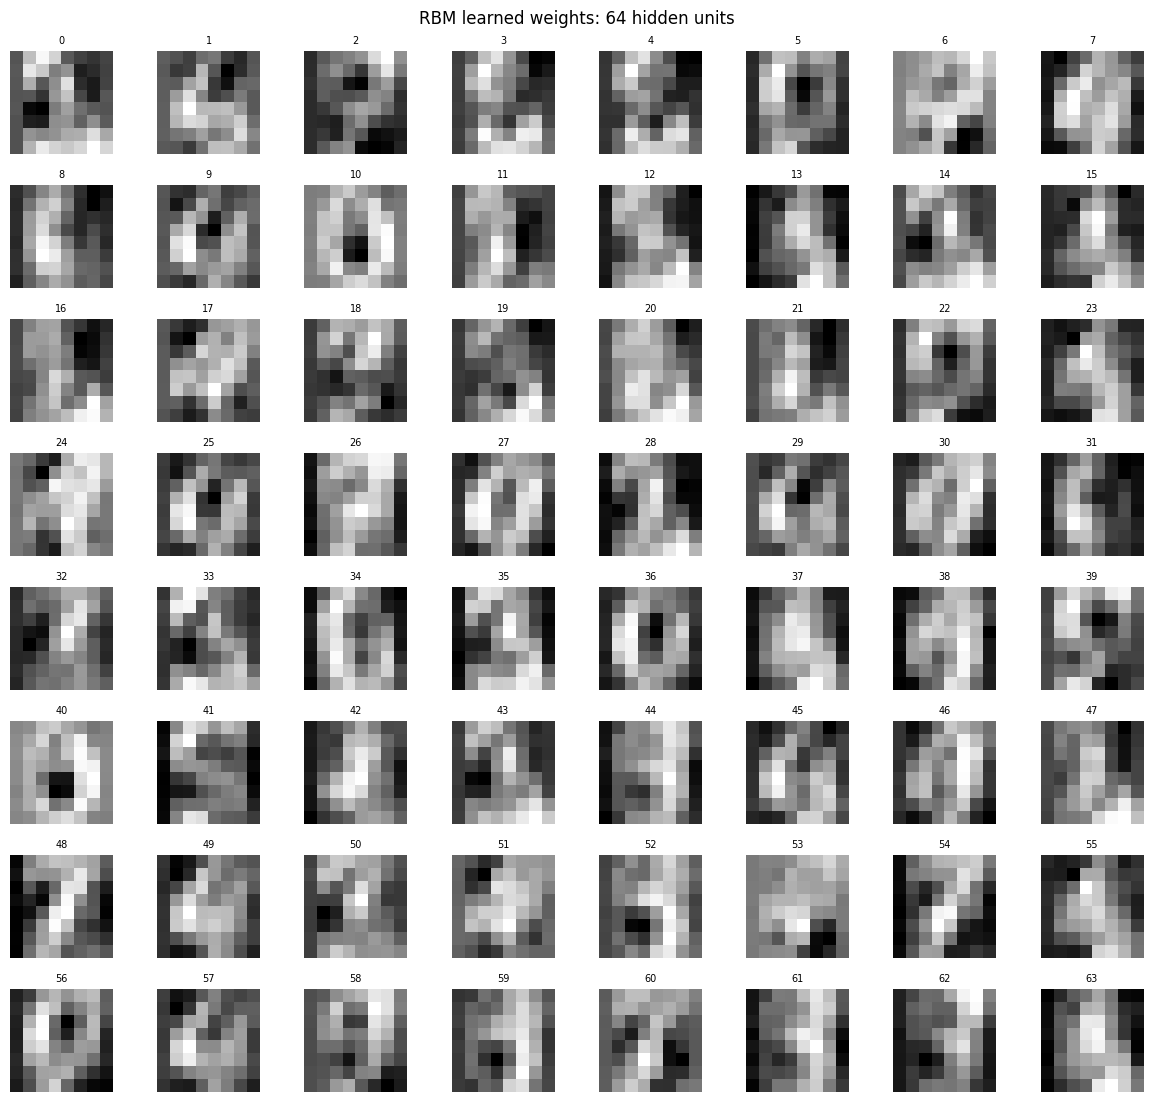

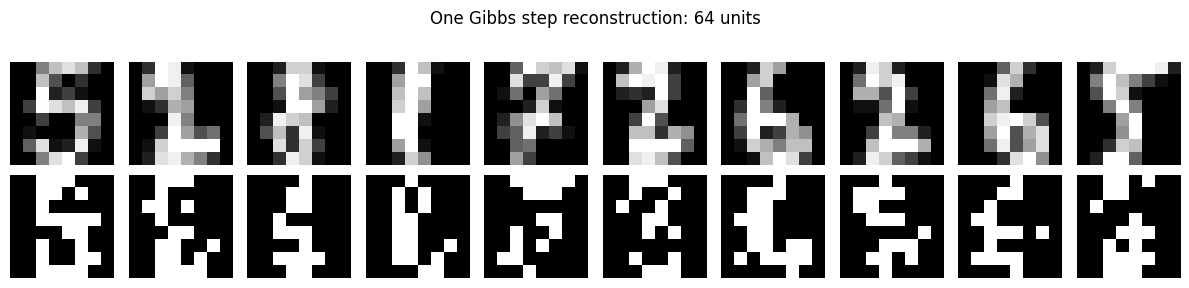

In [3]:
digits=load_digits()
Xd=digits.data.astype("float32")/16.0; yd=digits.target
Xtr,Xte,ytr,yte=train_test_split(Xd,yd,test_size=.2,random_state=SEED,stratify=yd)
q2models={}; rows=[]
for nh in [16,64]:
    model=BernoulliRBM(n_components=nh,learning_rate=.05,n_iter=20,batch_size=10,random_state=SEED)
    t=time.time(); model.fit(Xtr); elapsed=time.time()-t
    score=float(np.mean(model.score_samples(Xte)))
    q2models[nh]=model; rows.append([nh,.05,20,score,elapsed])
q2=pd.DataFrame(rows,columns=["hidden_units","learning_rate","iterations","average_test_pseudo_likelihood","training_seconds"])
display(q2); q2.to_csv(f"{OUT}/Q2_RBM_results.csv",index=False)
for nh,model in q2models.items():
    ncols=8; nrows=int(np.ceil(nh/ncols)); plt.figure(figsize=(12,nrows*1.4))
    for i,w in enumerate(model.components_):
        ax=plt.subplot(nrows,ncols,i+1); ax.imshow(w.reshape(8,8),cmap="gray"); ax.axis("off"); ax.set_title(str(i),fontsize=7)
    plt.suptitle(f"RBM learned weights: {nh} hidden units"); savefig(f"Q2_weights_{nh}.png")
    orig=Xte[:10]; rec=model.gibbs(orig.copy())
    plt.figure(figsize=(12,3))
    for i in range(10):
        plt.subplot(2,10,i+1); plt.imshow(orig[i].reshape(8,8),cmap="gray"); plt.axis("off")
        plt.subplot(2,10,11+i); plt.imshow(rec[i].reshape(8,8),cmap="gray"); plt.axis("off")
    plt.suptitle(f"One Gibbs step reconstruction: {nh} units"); savefig(f"Q2_gibbs_{nh}.png")

## Q3 – Deep Belief Networks with Few Labels

,seed,label_count,model,test_accuracy,training_seconds
0,21,100,Raw Logistic Regression,0.913889,0.154412
1,21,100,DBN Pipeline,0.158333,0.168812
2,21,500,Raw Logistic Regression,0.947222,0.208793
3,21,500,DBN Pipeline,0.100000,0.718331
4,21,1437,Raw Logistic Regression,0.955556,1.092879
5,21,1437,DBN Pipeline,0.711111,1.690956
6,42,100,Raw Logistic Regression,0.897222,0.036527
7,42,100,DBN Pipeline,0.138889,0.143786
8,42,500,Raw Logistic Regression,0.941667,0.136898
9,42,500,DBN Pipeline,0.141667,0.322646


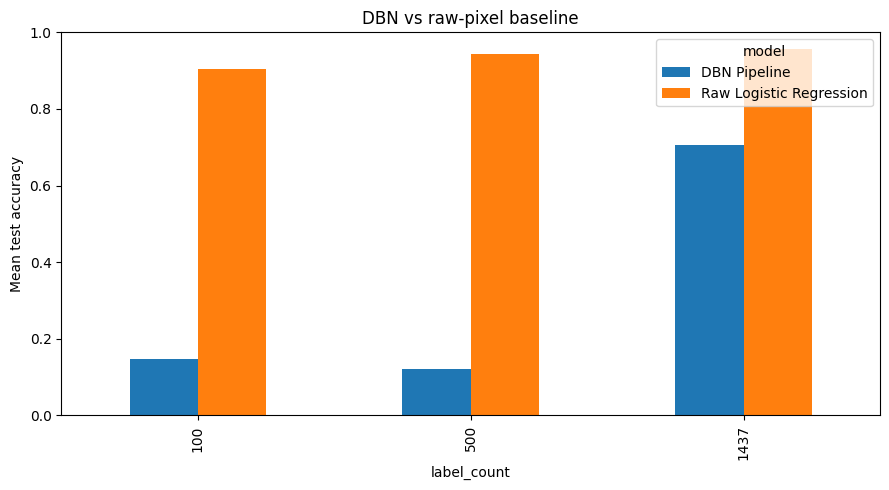

In [4]:
q3=[]; q3_models={}
for seed in [21,42]:
    for n in [100,500,len(ytr)]:
        if n==len(ytr): idx=np.arange(len(ytr))
        else: idx,_=train_test_split(np.arange(len(ytr)),train_size=n,random_state=seed,stratify=ytr)
        xa,ya=Xtr[idx],ytr[idx]
        base=LogisticRegression(max_iter=1500,solver="lbfgs",random_state=seed)
        t=time.time(); base.fit(xa,ya); tb=time.time()-t
        ab=accuracy_score(yte,base.predict(Xte))
        q3.append([seed,n,"Raw Logistic Regression",ab,tb])
        dbn=Pipeline([("rbm1",BernoulliRBM(n_components=64,learning_rate=.03,n_iter=15,batch_size=10,random_state=seed)),
                      ("rbm2",BernoulliRBM(n_components=32,learning_rate=.03,n_iter=15,batch_size=10,random_state=seed+1)),
                      ("logistic",LogisticRegression(max_iter=1500,solver="lbfgs",random_state=seed))])
        t=time.time(); dbn.fit(xa,ya); td=time.time()-t
        ad=accuracy_score(yte,dbn.predict(Xte))
        q3.append([seed,n,"DBN Pipeline",ad,td]); q3_models[(seed,n)]=(base,dbn)
q3=pd.DataFrame(q3,columns=["seed","label_count","model","test_accuracy","training_seconds"])
display(q3); q3.to_csv(f"{OUT}/Q3_DBN_comparison.csv",index=False)
mean=q3.groupby(["label_count","model"]).test_accuracy.mean().reset_index()
pv=mean.pivot(index="label_count",columns="model",values="test_accuracy")
pv.plot(kind="bar",figsize=(9,5),ylim=(0,1),ylabel="Mean test accuracy",title="DBN vs raw-pixel baseline")
savefig("Q3_accuracy_bar_chart.png")

## Q4 – Generating Images with a Variational Autoencoder

Epoch 1/12
469/469 - 10s - 21ms/step - kl_loss: 6.5132 - loss: 290.8667 - reconstruction_loss: 284.3535 - val_kl_loss: 6.6032 - val_loss: 279.4514 - val_reconstruction_loss: 272.8481
Epoch 2/12
469/469 - 8s - 17ms/step - kl_loss: 6.3980 - loss: 286.0364 - reconstruction_loss: 279.6384 - val_kl_loss: 6.2017 - val_loss: 274.3774 - val_reconstruction_loss: 268.1757
Epoch 3/12
469/469 - 8s - 18ms/step - kl_loss: 6.3333 - loss: 283.0254 - reconstruction_loss: 276.6921 - val_kl_loss: 6.1113 - val_loss: 270.6259 - val_reconstruction_loss: 264.5146
Epoch 4/12
469/469 - 7s - 15ms/step - kl_loss: 6.4320 - loss: 281.3036 - reconstruction_loss: 274.8716 - val_kl_loss: 5.9898 - val_loss: 267.1178 - val_reconstruction_loss: 261.1279
Epoch 5/12
469/469 - 8s - 16ms/step - kl_loss: 6.2661 - loss: 280.2278 - reconstruction_loss: 273.9616 - val_kl_loss: 5.9735 - val_loss: 266.0521 - val_reconstruction_loss: 260.0786
Epoch 6/12
469/469 - 8s - 17ms/step - kl_loss: 6.1125 - loss: 278.4911 - reconstruction_l

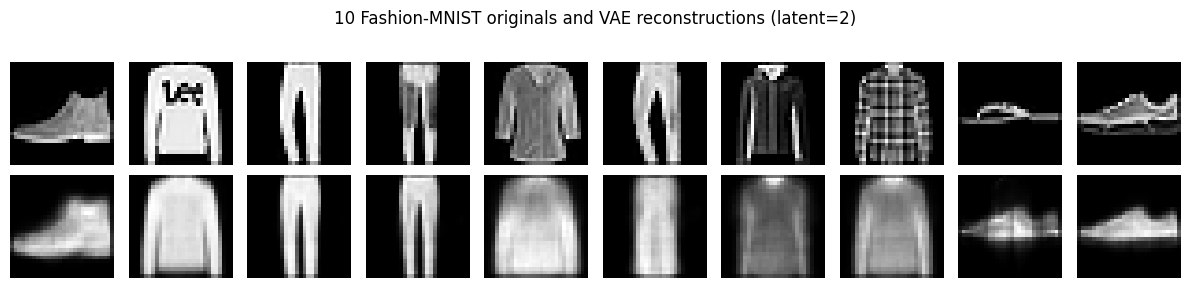

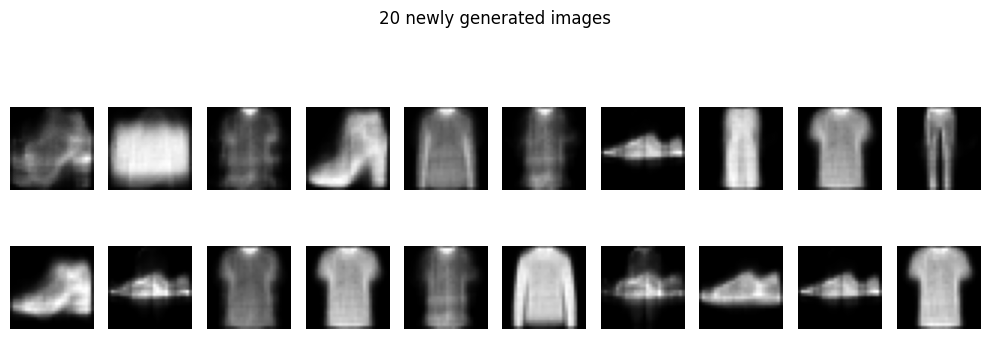

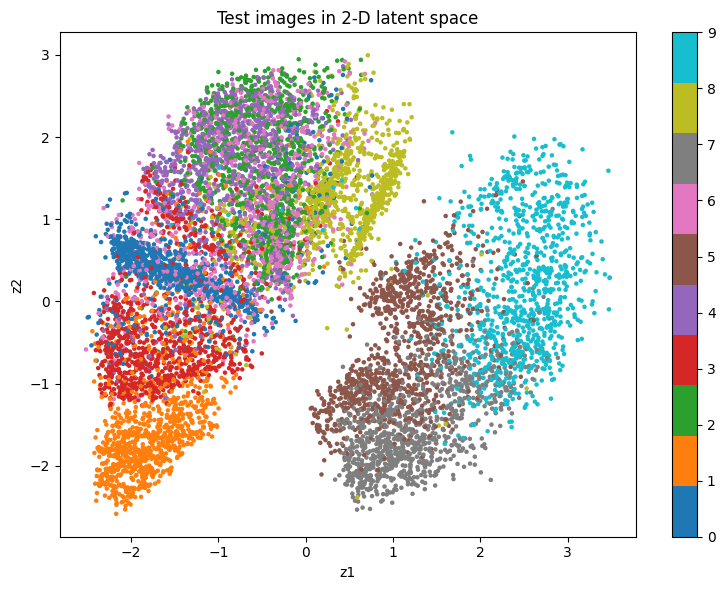

,latent_size,test_reconstruction_MAE,parameter_count
0,2,0.101689,404244
1,16,0.068771,415024


In [9]:
(xtrain,ytrain),(xtest,ytest)=keras.datasets.fashion_mnist.load_data()
xtrain=(xtrain.astype("float32")/255.)[...,None]; xtest=(xtest.astype("float32")/255.)[...,None]
fashion_names=["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]
def build_vae(ld):
    inp=keras.Input((28,28,1)); x=layers.Flatten()(inp); x=layers.Dense(256,activation="relu")(x)
    mu=layers.Dense(ld)(x); lv=layers.Dense(ld)(x)
    def sample(args):
        m,l=args; return m+tf.exp(.5*l)*tf.random.normal(tf.shape(m))
    z=layers.Lambda(sample)([mu,lv]); enc=keras.Model(inp,[mu,lv,z])
    zi=keras.Input((ld,)); d=layers.Dense(256,activation="relu")(zi); d=layers.Dense(784,activation="sigmoid")(d)
    dec=keras.Model(zi,layers.Reshape((28,28,1))(d))
    class VAE(keras.Model):
        def __init__(self): super().__init__(); self.enc=enc; self.dec=dec
        def call(self, inputs):
            _, _, z = self.enc(inputs)
            return self.dec(z)
        def train_step(self,data):
            if isinstance(data,tuple): data=data[0]
            with tf.GradientTape() as tape:
                m,l,z=self.enc(data,training=True); r=self.dec(z,training=True)
                rec=tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(data,r),axis=(1,2)))
                kl=-.5*tf.reduce_mean(tf.reduce_sum(1+l-tf.square(m)-tf.exp(l),axis=1)); loss=rec+kl
            g=tape.gradient(loss,self.trainable_weights); self.optimizer.apply_gradients(zip(g,self.trainable_weights))
            return {"loss":loss,"reconstruction_loss":rec,"kl_loss":kl}
        def test_step(self,data):
            if isinstance(data,tuple): data=data[0]
            m,l,z=self.enc(data,training=False); r=self.dec(z,training=False)
            rec=tf.reduce_mean(tf.reduce_sum(keras.losses.binary_crossentropy(data,r),axis=(1,2)))
            kl=-.5*tf.reduce_mean(tf.reduce_sum(1+l-tf.square(m)-tf.exp(l),axis=1)); loss=rec+kl
            return {"loss":loss,"reconstruction_loss":rec,"kl_loss":kl}
    vae=VAE(); return vae,enc,dec
vaes={}
for ld in [2,16]:
    vae,enc,dec=build_vae(ld); vae.compile(optimizer=keras.optimizers.Adam(1e-3))
    t=time.time(); hist=vae.fit(xtrain,epochs=12,batch_size=128,validation_data=(xtest,None),verbose=2)
    vaes[ld]=(vae,enc,dec); pd.DataFrame(hist.history).to_csv(f"{OUT}/Q4_VAE_history_{ld}.csv",index=False)
    vae.build((None,28,28,1))
    print("latent",ld,"training seconds",time.time()-t,"parameters",vae.count_params())
vae2,enc2,dec2=vaes[2]
mu,lv,z=enc2.predict(xtest[:10],verbose=0); rec=dec2.predict(z,verbose=0)
plt.figure(figsize=(12,3))
for i in range(10):
    plt.subplot(2,10,i+1); plt.imshow(xtest[i].squeeze(),cmap="gray"); plt.axis("off")
    plt.subplot(2,10,11+i); plt.imshow(rec[i].squeeze(),cmap="gray"); plt.axis("off")
plt.suptitle("10 Fashion-MNIST originals and VAE reconstructions (latent=2)"); savefig("Q4_reconstructions.png")
gen20=dec2.predict(np.random.normal(size=(20,2)).astype("float32"),verbose=0)
plt.figure(figsize=(10,4))
for i in range(20): plt.subplot(2,10,i+1); plt.imshow(gen20[i].squeeze(),cmap="gray"); plt.axis("off")
plt.suptitle("20 newly generated images"); savefig("Q4_generated_20.png")
mut,_,_=enc2.predict(xtest,batch_size=256,verbose=0)
plt.figure(figsize=(8,6)); sc=plt.scatter(mut[:,0],mut[:,1],c=ytest,s=5,cmap="tab10"); plt.colorbar(sc); plt.xlabel("z1"); plt.ylabel("z2"); plt.title("Test images in 2-D latent space"); savefig("Q4_latent_space.png")
q4=[]
for ld,(v,e,d) in vaes.items():
    m,l,z=e.predict(xtest,batch_size=256,verbose=0); r=d.predict(z,batch_size=256,verbose=0)
    q4.append([ld,float(np.mean(np.abs(xtest-r))),v.count_params()])
q4=pd.DataFrame(q4,columns=["latent_size","test_reconstruction_MAE","parameter_count"]); display(q4); q4.to_csv(f"{OUT}/Q4_VAE_comparison.csv",index=False)

## Q5 – Comparing a GAN with the VAE

1 D 0.5759195285056954 G 2.1624040514675538
2 D 0.5631530752568357 G 2.258732533658237
3 D 0.5678765142141883 G 2.3866032280647422
4 D 0.5394769999772501 G 2.572949299425967
5 D 0.55904232502492 G 2.5622235475572697
6 D 0.6271362895650396 G 2.3651200512579003
7 D 0.6742415634045469 G 2.2108205246772847
8 D 0.680560183042148 G 2.149443257083771
9 D 0.6703019090044473 G 2.2479877121158753
10 D 0.659271810100531 G 2.2391698228270767
11 D 0.6804713581416653 G 2.2002648234621547
12 D 0.7485411240856277 G 1.9944431123448843
13 D 0.7866432551127761 G 1.860010994776988
14 D 0.7960542401016902 G 1.8519631184494572
15 D 0.8203872507060769 G 1.7656355609517616


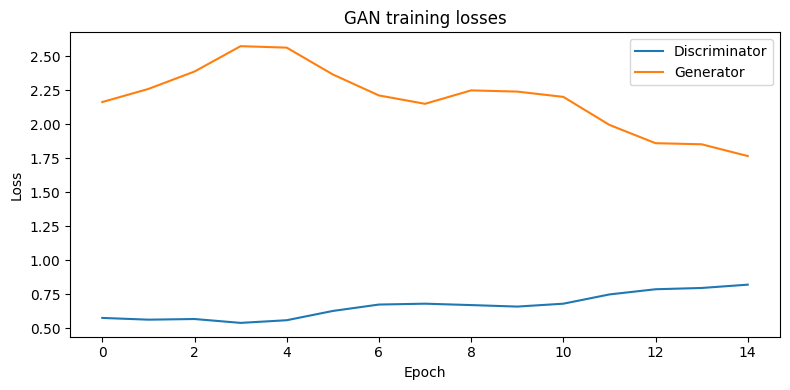

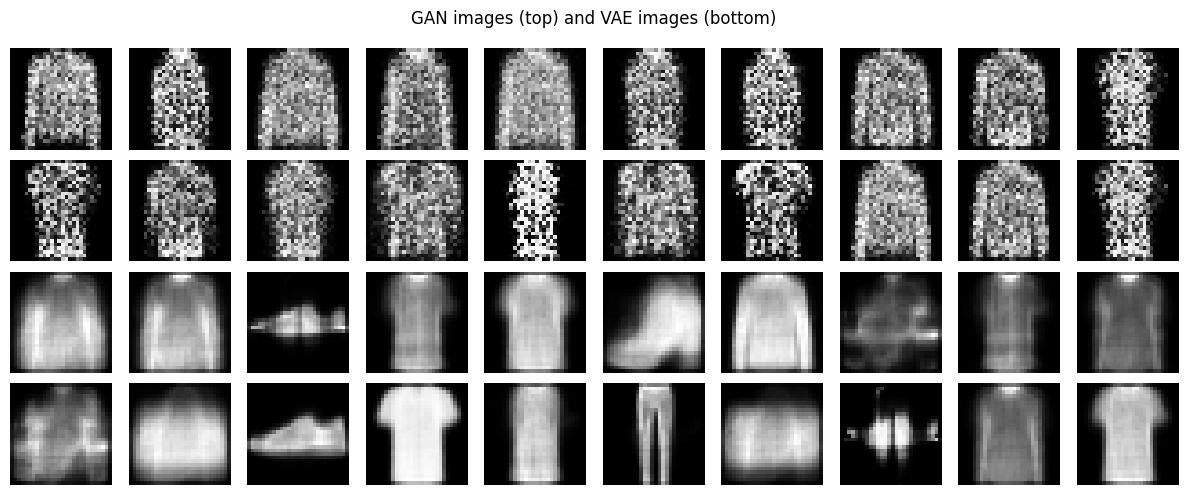

In [10]:
ZDIM=64
generator=keras.Sequential([layers.Input((ZDIM,)),layers.Dense(256,activation="relu"),
    layers.Dense(512,activation="relu"),layers.Dense(784,activation="sigmoid"),layers.Reshape((28,28,1))],name="Generator")
discriminator=keras.Sequential([layers.Input((28,28,1)),layers.Flatten(),layers.Dense(512),
    layers.LeakyReLU(negative_slope=.2),layers.Dense(256),layers.LeakyReLU(negative_slope=.2),
    layers.Dense(1,activation="sigmoid")],name="Discriminator")
bce=keras.losses.BinaryCrossentropy(); go=keras.optimizers.Adam(1e-4,beta_1=.5); do=keras.optimizers.Adam(1e-4,beta_1=.5)
@tf.function
def gan_step(real):
    bs=tf.shape(real)[0]; noise=tf.random.normal([bs,ZDIM])
    with tf.GradientTape() as dt,tf.GradientTape() as gt:
        fake=generator(noise,training=True); ro=discriminator(real,training=True); fo=discriminator(fake,training=True)
        dl=bce(tf.ones_like(ro)*.9,ro)+bce(tf.zeros_like(fo),fo); gl=bce(tf.ones_like(fo),fo)
    dg=dt.gradient(dl,discriminator.trainable_variables); gg=gt.gradient(gl,generator.trainable_variables)
    do.apply_gradients(zip(dg,discriminator.trainable_variables)); go.apply_gradients(zip(gg,generator.trainable_variables))
    return dl,gl
ds=tf.data.Dataset.from_tensor_slices(xtrain).shuffle(10000,seed=SEED).batch(128).prefetch(tf.data.AUTOTUNE)
dlog=[]; glog=[]
for ep in range(15):
    a=[]; b=[]
    for batch in ds:
        dl,gl=gan_step(batch); a.append(float(dl)); b.append(float(gl))
    dlog.append(np.mean(a)); glog.append(np.mean(b)); print(ep+1,"D",dlog[-1],"G",glog[-1])
pd.DataFrame({"epoch":np.arange(1,16),"discriminator_loss":dlog,"generator_loss":glog}).to_csv(f"{OUT}/Q5_GAN_losses.csv",index=False)
plt.figure(figsize=(8,4)); plt.plot(dlog,label="Discriminator"); plt.plot(glog,label="Generator"); plt.legend(); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("GAN training losses"); savefig("Q5_GAN_losses.png")
g20=generator.predict(np.random.normal(size=(20,ZDIM)).astype("float32"),verbose=0)
v20=dec2.predict(np.random.normal(size=(20,2)).astype("float32"),verbose=0)
plt.figure(figsize=(12,5))
for i in range(20):
    plt.subplot(4,10,i+1); plt.imshow(g20[i].squeeze(),cmap="gray"); plt.axis("off")
    plt.subplot(4,10,21+i); plt.imshow(v20[i].squeeze(),cmap="gray"); plt.axis("off")
plt.suptitle("GAN images (top) and VAE images (bottom)"); savefig("Q5_GAN_vs_VAE.png")

## Q6 – Generative Model Mini-Investigations

Epoch 1/5
422/422 - 46s - 108ms/step - accuracy: 0.7936 - loss: 0.5726 - val_accuracy: 0.8538 - val_loss: 0.4048
Epoch 2/5
422/422 - 82s - 194ms/step - accuracy: 0.8692 - loss: 0.3619 - val_accuracy: 0.8792 - val_loss: 0.3355
Epoch 3/5
422/422 - 43s - 103ms/step - accuracy: 0.8861 - loss: 0.3127 - val_accuracy: 0.8917 - val_loss: 0.2974
Epoch 4/5
422/422 - 44s - 104ms/step - accuracy: 0.8974 - loss: 0.2802 - val_accuracy: 0.9000 - val_loss: 0.2733
Epoch 5/5
422/422 - 43s - 102ms/step - accuracy: 0.9061 - loss: 0.2556 - val_accuracy: 0.9048 - val_loss: 0.2612
Real test classifier accuracy: 0.9016000032424927


,generator,average_confidence,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
0,GAN,0.771852,3,0,0,72,2,0,123,0,0,0
1,VAE,0.629358,32,13,36,9,0,0,3,39,36,32


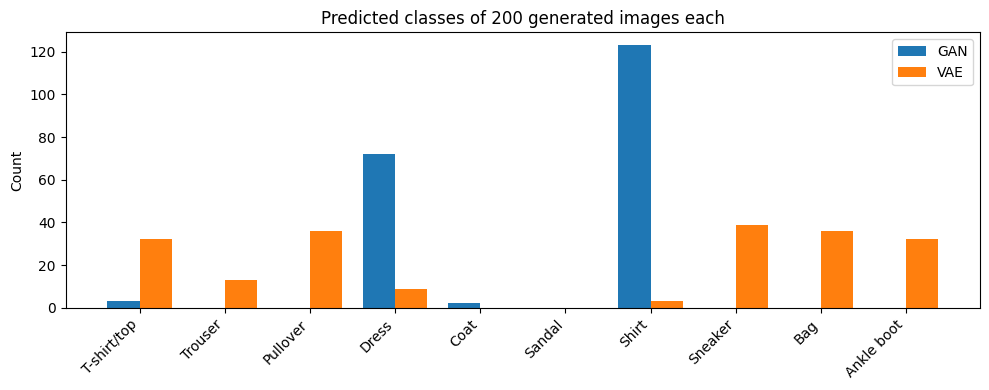

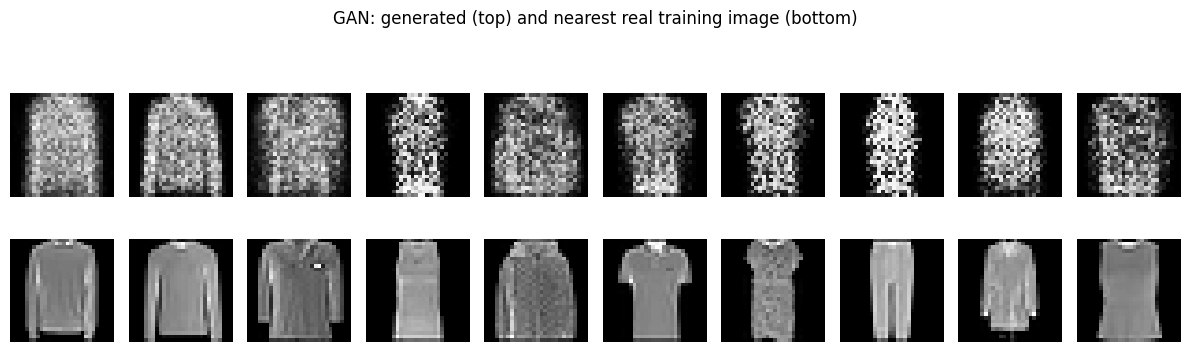

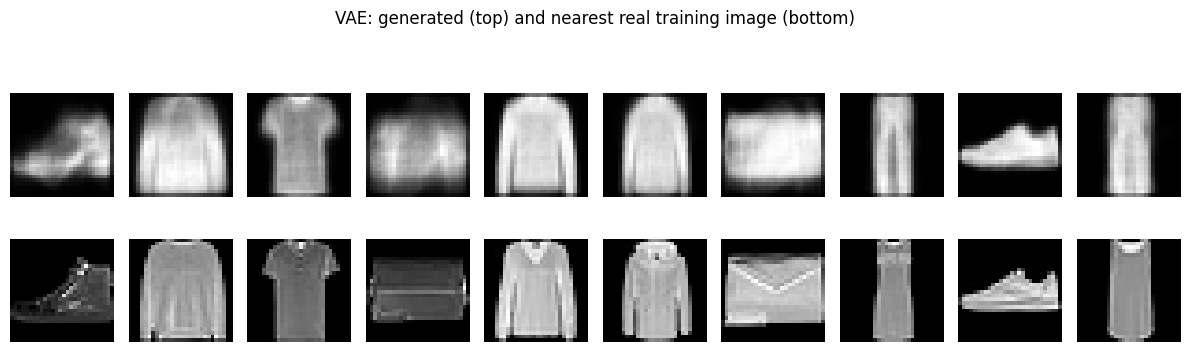

,generator,generated_index,nearest_training_index,euclidean_distance
0,GAN,0,59944,3.826099
1,GAN,1,28206,4.018156
2,GAN,2,39798,4.711713
3,GAN,3,41416,5.979853
4,GAN,4,20529,4.988894
5,GAN,5,27981,4.618581
6,GAN,6,55820,5.786191
7,GAN,7,8686,6.435813
8,GAN,8,36309,5.373753
9,GAN,9,57519,5.623235


,model,weight_count
0,Fully connected RBM,392000
1,"Convolutional RBM (16 filters, 5x5)",400


Weight reduction factor: 980.0


In [11]:
# Student A: classifier trained only on real Fashion-MNIST images
clf=keras.Sequential([layers.Input((28,28,1)),layers.Conv2D(32,3,activation="relu"),layers.MaxPooling2D(),
    layers.Conv2D(64,3,activation="relu"),layers.MaxPooling2D(),layers.Flatten(),
    layers.Dense(128,activation="relu"),layers.Dense(10,activation="softmax")])
clf.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
clf.fit(xtrain,ytrain,epochs=5,batch_size=128,validation_split=.1,verbose=2)
_,clf_acc=clf.evaluate(xtest,ytest,verbose=0); print("Real test classifier accuracy:",clf_acc)
g200=generator.predict(np.random.normal(size=(200,ZDIM)).astype("float32"),verbose=0)
v200=dec2.predict(np.random.normal(size=(200,2)).astype("float32"),verbose=0)
pg=clf.predict(g200,verbose=0); pv=clf.predict(v200,verbose=0)
def gen_summary(prob,name):
    labels=np.argmax(prob,axis=1); counts=np.bincount(labels,minlength=10)
    return [name,float(np.max(prob,axis=1).mean()),*counts]
q6dist=pd.DataFrame([gen_summary(pg,"GAN"),gen_summary(pv,"VAE")],
    columns=["generator","average_confidence"]+fashion_names)
display(q6dist); q6dist.to_csv(f"{OUT}/Q6_generated_class_distribution.csv",index=False)
plt.figure(figsize=(10,4)); x=np.arange(10); w=.38
plt.bar(x-w/2,np.bincount(np.argmax(pg,axis=1),minlength=10),w,label="GAN")
plt.bar(x+w/2,np.bincount(np.argmax(pv,axis=1),minlength=10),w,label="VAE")
plt.xticks(x,fashion_names,rotation=45,ha="right"); plt.ylabel("Count"); plt.legend(); plt.title("Predicted classes of 200 generated images each"); savefig("Q6_class_distribution.png")
# Nearest real training images for ten samples from each generator
nn=NearestNeighbors(n_neighbors=1,metric="euclidean").fit(xtrain.reshape(len(xtrain),-1))
copyrows=[]
for name,imgs in [("GAN",g200),("VAE",v200)]:
    dist,ind=nn.kneighbors(imgs[:10].reshape(10,-1))
    for i in range(10): copyrows.append([name,i,int(ind[i,0]),float(dist[i,0])])
    plt.figure(figsize=(12,4))
    for i in range(10):
        plt.subplot(2,10,i+1); plt.imshow(imgs[i].squeeze(),cmap="gray"); plt.axis("off")
        plt.subplot(2,10,11+i); plt.imshow(xtrain[ind[i,0]].squeeze(),cmap="gray"); plt.axis("off")
    plt.suptitle(name+": generated (top) and nearest real training image (bottom)"); savefig(f"Q6_{name}_nearest.png")
q6copy=pd.DataFrame(copyrows,columns=["generator","generated_index","nearest_training_index","euclidean_distance"])
display(q6copy); q6copy.to_csv(f"{OUT}/Q6_nearest_neighbours.csv",index=False)

# Student B: RBM parameter-count comparison
fc=28*28*500; conv=16*5*5
q6counts=pd.DataFrame([["Fully connected RBM",fc],["Convolutional RBM (16 filters, 5x5)",conv]],columns=["model","weight_count"])
display(q6counts); print("Weight reduction factor:",fc/conv)
q6counts.to_csv(f"{OUT}/Q6_RBM_weight_counts.csv",index=False)

## Q7 – Generate Images for a New Product Category

Training images: 300
Epoch 10 D 0.567009511590004 G 2.442309594154358
Epoch 20 D 0.6638633668422699 G 1.93456529378891
Epoch 30 D 0.6361565887928009 G 1.8716447949409485
Epoch 40 D 0.5549440562725068 G 2.18838552236557
Epoch 50 D 0.5243088006973267 G 2.3361677169799804
Epoch 60 D 0.546308946609497 G 2.239556837081909
Epoch 70 D 0.5527868568897247 G 2.200253164768219
Epoch 80 D 0.6020999073982238 G 2.0401401996612547
Epoch 90 D 0.5846780955791473 G 2.100800335407257
Epoch 100 D 0.5888483107089997 G 2.050866401195526


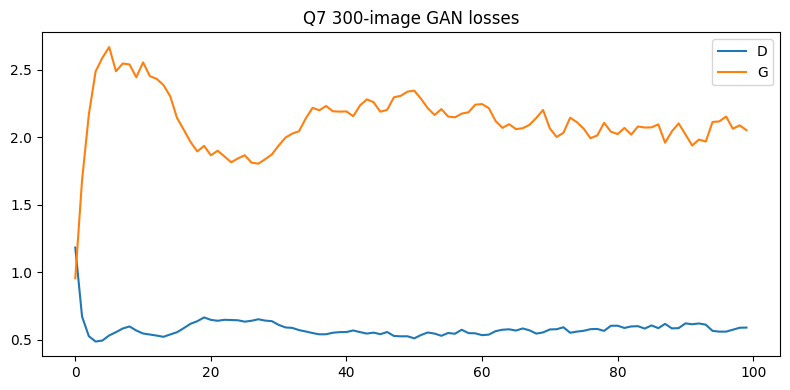

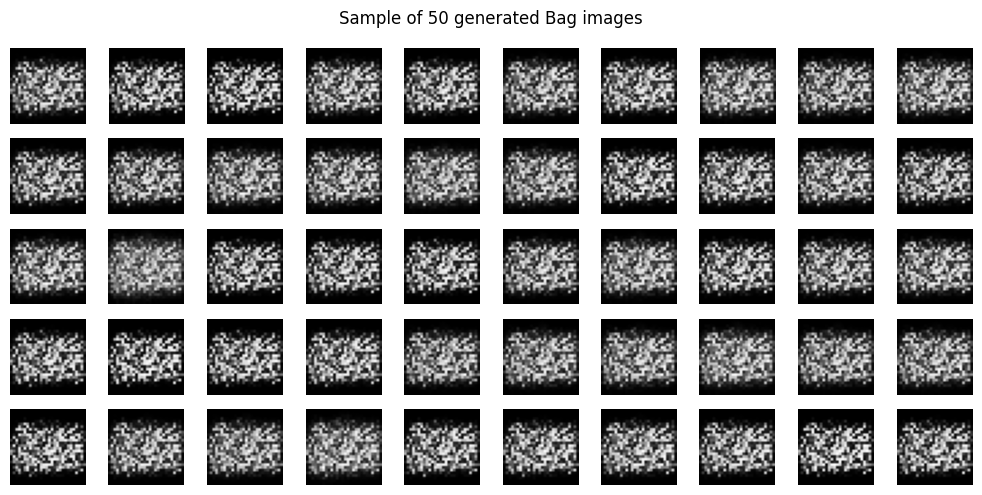

,generated_index,nearest_bag_index,nearest_distance,threshold,flagged_near_copy
0,0,232,7.184786,1.4,False
1,1,111,7.796260,1.4,False
2,2,111,8.225827,1.4,False
3,3,232,7.183547,1.4,False
4,4,111,7.591552,1.4,False
5,5,232,7.039133,1.4,False
6,6,111,7.429168,1.4,False
7,7,232,6.743933,1.4,False
8,8,232,7.059569,1.4,False
9,9,232,6.767321,1.4,False


Threshold 1.4000000000000001 flagged 0 of 1000
Predicted as Bag: 1000 /1000; mean confidence: 0.77558434009552
Generator parameters: 238736 Discriminator parameters: 233985


In [12]:
# Use 300 Fashion-MNIST Bag images (class index 8); train a compact GAN.
bag=xtrain[np.where(ytrain==8)[0][:300]]
print("Training images:",len(bag))
QZ=32
qg=keras.Sequential([layers.Input((QZ,)),layers.Dense(128,activation="relu"),
    layers.Dense(256,activation="relu"),layers.Dense(784,activation="sigmoid"),layers.Reshape((28,28,1))],name="Q7_Bag_Generator")
qd=keras.Sequential([layers.Input((28,28,1)),layers.Flatten(),layers.Dense(256),
    layers.LeakyReLU(negative_slope=.2),layers.Dense(128),layers.LeakyReLU(negative_slope=.2),
    layers.Dense(1,activation="sigmoid")],name="Q7_Bag_Discriminator")
qgo=keras.optimizers.Adam(1e-4,beta_1=.5); qdo=keras.optimizers.Adam(1e-4,beta_1=.5); qbce=keras.losses.BinaryCrossentropy()
@tf.function
def qstep(real):
    bs=tf.shape(real)[0]; noise=tf.random.normal([bs,QZ])
    with tf.GradientTape() as dt,tf.GradientTape() as gt:
        fake=qg(noise,training=True); ro=qd(real,training=True); fo=qd(fake,training=True)
        dl=qbce(tf.ones_like(ro)*.9,ro)+qbce(tf.zeros_like(fo),fo); gl=qbce(tf.ones_like(fo),fo)
    dg=dt.gradient(dl,qd.trainable_variables); gg=gt.gradient(gl,qg.trainable_variables)
    qdo.apply_gradients(zip(dg,qd.trainable_variables)); qgo.apply_gradients(zip(gg,qg.trainable_variables))
    return dl,gl
qds=tf.data.Dataset.from_tensor_slices(bag).shuffle(300,seed=SEED).repeat().batch(32)
qdl=[]; qgl=[]; steps=int(np.ceil(300/32))
for ep in range(100):
    aa=[]; bb=[]
    for batch in qds.take(steps):
        dl,gl=qstep(batch); aa.append(float(dl)); bb.append(float(gl))
    qdl.append(np.mean(aa)); qgl.append(np.mean(bb))
    if (ep+1)%10==0: print("Epoch",ep+1,"D",qdl[-1],"G",qgl[-1])
pd.DataFrame({"epoch":np.arange(1,101),"D_loss":qdl,"G_loss":qgl}).to_csv(f"{OUT}/Q7_training_losses.csv",index=False)
plt.figure(figsize=(8,4)); plt.plot(qdl,label="D"); plt.plot(qgl,label="G"); plt.legend(); plt.title("Q7 300-image GAN losses"); savefig("Q7_losses.png")
# Generate 1,000 images
generated=qg.predict(np.random.normal(size=(1000,QZ)).astype("float32"),verbose=0)
np.save(f"{OUT}/Q7_generated_1000_bags.npy",generated)
plt.figure(figsize=(10,5))
for i in range(50): plt.subplot(5,10,i+1); plt.imshow(generated[i].squeeze(),cmap="gray"); plt.axis("off")
plt.suptitle("Sample of 50 generated Bag images"); savefig("Q7_generated_sample.png")
# Nearest-copy check against the 300 real Bag images.
bag_nn=NearestNeighbors(n_neighbors=1,metric="euclidean").fit(bag.reshape(300,-1))
dist,ind=bag_nn.kneighbors(generated.reshape(1000,-1))
# Predeclared operational threshold: 5% of maximum 28x28 grayscale Euclidean distance.
threshold=.05*np.sqrt(28*28)
flag=dist[:,0]<threshold
q7copy=pd.DataFrame({"generated_index":np.arange(1000),"nearest_bag_index":ind[:,0],
    "nearest_distance":dist[:,0],"threshold":threshold,"flagged_near_copy":flag})
display(q7copy.head(20)); print("Threshold",threshold,"flagged",int(flag.sum()),"of 1000")
q7copy.to_csv(f"{OUT}/Q7_copy_check.csv",index=False)
# Q6 classifier cross-check: how many are recognised as Bags?
q7prob=clf.predict(generated,verbose=0); q7pred=np.argmax(q7prob,axis=1); q7conf=np.max(q7prob,axis=1)
print("Predicted as Bag:",int(np.sum(q7pred==8)),"/1000; mean confidence:",float(q7conf.mean()))
pd.DataFrame({"predicted_class":q7pred,"predicted_name":[fashion_names[i] for i in q7pred],
              "confidence":q7conf}).to_csv(f"{OUT}/Q7_classifier_validation.csv",index=False)
print("Generator parameters:",qg.count_params(),"Discriminator parameters:",qd.count_params())

## Export all tables, graphs and generated samples

In [13]:
summary={"tensorflow":tf.__version__,"sklearn":sklearn.__version__,"Q1_Z":float(Z),
         "Q2_mean_pseudo_likelihood":q2.to_dict(orient="records"),
         "Q3_results":q3.to_dict(orient="records"),"Q4_results":q4.to_dict(orient="records"),
         "Q6_classifier_test_accuracy":float(clf_acc),"Q7_generated_count":len(generated),
         "Q7_copy_threshold":float(threshold),"Q7_flagged_count":int(flag.sum()),
         "Q7_bag_classifier_count":int(np.sum(q7pred==8))}
with open(f"{OUT}/run_summary.json","w") as f: json.dump(summary,f,indent=2)
zip_path="/content/Assignment5_CO5_Results.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for root,dirs,files in os.walk(OUT):
        for fn in files:
            full=os.path.join(root,fn); z.write(full,arcname=os.path.relpath(full,OUT))
print("ZIP ready:",zip_path)
from google.colab import files
files.download(zip_path)

ZIP ready: /content/Assignment5_CO5_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>